# 01 - Load and inspect: IEEE-CIS Fraud Data

**Purpose:** before any modelling, check the data matches its documentation, understand the class balance and missing data, and decide how to the train/test split should work

In [1]:
# Import the packages used in this notebook
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Read the two raw files
# tx = transaction table: one row per transaction, includes the target variable 'isFraud'
# idn = identity table: device/browser details, only recorded for some transactions
tx = pd.read_csv("../data/train_transaction.csv")
idn = pd.read_csv("../data/train_identity.csv")

In [3]:
# The two tables join on TransactionID. If an ID were duplicated, the merge would silently create extra rows
# and distort every rate calculated later, so we check uniqueness here.
print("Duplicate IDs in transactions:", tx['TransactionID'].duplicated().sum())
print("Duplicate IDs in identity:", idn['TransactionID'].duplicated().sum())

# Confirm the target is strictly binary with no missing values.
print(tx['isFraud'].value_counts(dropna=False))

Duplicate IDs in transactions: 0
Duplicate IDs in identity: 0
isFraud
0    569877
1     20663
Name: count, dtype: int64


Both ID columns show 0 duplicates and isFraud only contains 0 and 1. So, the join key is safe and the target needs no cleaning

In [4]:
# A left join is used to keep every transaction and attach identity info where it exists.
df = tx.merge(idn, on="TransactionID", how="left")

# Sanity check: a left join on a unique key should not change the number of rows.
print("Rows before:", len(tx))
print("Rows after merge:", len(df))
assert len(tx) == len(df)

Rows before: 590540
Rows after merge: 590540


In [5]:
# The mean of a 0/1 column is the proportion 1s, so this is the overall fraud rate.
fraud_rate = df['isFraud'].mean()
print(f"Fraud rate: {fraud_rate:.4%}")

# Benchmark: the accuracy of a model that predicts 'not fraud' for every transaction
# Any model must beat this to be useful, and it shows why accuracy is a poor metric for this problem.
print(f"Benchmark accuracy: {1 - fraud_rate:.4%}")

Fraud rate: 3.4990%
Benchmark accuracy: 96.5010%


About 3.5% of the transactions are fraud, so the classes are heavily imbalanced. A model that never flags anything would be roughly 96.5% accurate whilst catching zero fraud. Accuracy is therefore not a useful metric for this project. I will use precision-recall measures and, later, a cost-based measure that values missed fraud against false declines

In [6]:
# Flag whether each transaction has a matching row in the identity table
df['has_identity'] = df['TransactionID'].isin(idn['TransactionID'])
print(f"Share of transactions with identity data: {df['has_identity'].mean():.4%}")

# Does the fraud rate differ for transactions with and without identity data?
# If it does, 'being missed' is itself informative and shouldn't be treated as random noise
print(df.groupby('has_identity')['isFraud'].agg(['count', 'mean']))


Share of transactions with identity data: 24.4239%
               count      mean
has_identity                  
False         446307  0.020939
True          144233  0.078470


Roughly a quarter (24.4%) of transactions have identity data, so a left join was the right choice.
Fraud rate with identity data: **7.85%**. Without **2.09%**
The gap is large, hence missigness is informative and should be included as a feature

In [7]:
# TranactionDT is an offset in seconds from an arbitrary reference point, so we can convert it to days to be more interpretable
df['day'] = df['TransactionDT'] // (3600 * 24)
print(f"Days spanned: {df['day'].max() - df['day'].min():1f}")

# Grorup into 7-day weeks to see whether volume and fraud rate are stable over time
df['week'] = (df['TransactionDT'] // (3600 * 24 * 7)).astype(int)
weekly = df.groupby('week')['isFraud'].agg(['count', 'mean'])
weekly.columns = ['transaction_count', 'fraud_rate']

# Look at the first and last 5 rows. (The final week may only be partly filled)
print(weekly.head(5))
print(weekly.tail(5))

Days spanned: 181.000000
      transaction_count  fraud_rate
week                               
0                 23810    0.028055
1                 27803    0.026148
2                 34470    0.025500
3                 37251    0.018523
4                 24041    0.038226
      transaction_count  fraud_rate
week                               
22                20740    0.028496
23                20944    0.032515
24                20206    0.036672
25                17681    0.041627
26                 2754    0.043210


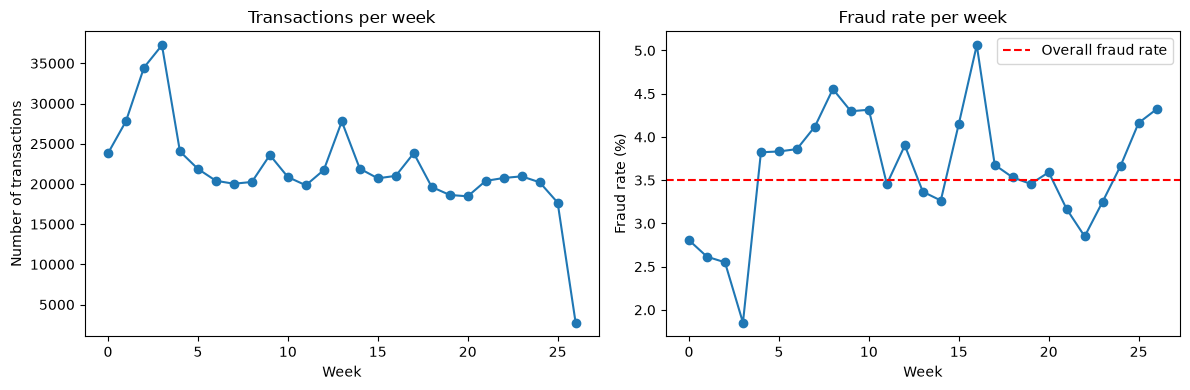

In [8]:
# Plot weekly volume and fraud rate side-by-side
# Dashed red line is the overall fraud rate to compare to
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(weekly.index, weekly['transaction_count'], marker='o')
axes[0].set_title('Transactions per week')
axes[0].set_xlabel('Week')
axes[0].set_ylabel('Number of transactions')

axes[1].plot(weekly.index, weekly['fraud_rate']*100, marker='o')
axes[1].axhline(fraud_rate*100, color='red', linestyle='--', label='Overall fraud rate')
axes[1].set_title('Fraud rate per week')
axes[1].set_xlabel('Week')
axes[1].set_ylabel('Fraud rate (%)')
axes[1].legend()

plt.tight_layout()
plt.show()

## Findings
- **Size and structure:** 590k transactions across around 182 days (26 weeks). The data is consistent, with TransactionDT being in seconds. It is not a calendar date, so it's not possible to link fraud to real world events
- **Heavy class imbalance:** 3.5% fraud rate. Naive model predicting fraud every time give 96.5% accuracy, so accuracy is not a useful measure here.
- **Identity data is patchy:** present for around a quarter of transactions. Fraud rate differs between the two groups, which suggests that missing identity data may carry a signal.
- **Stability over time:** Weekly volume tends to hover between 20-25k but has a big peak near the beginning. The sudden drop off at the end is not a worry as it's due to partial data. Weekly fraud rate seems to be quite unstable, ranging from 2% to 5%.

## Assumptions and limitations
- I treat TransactionDT as seconds, as taken from the Kaggle competition details.
- No calendar dates, so no day-of-week or seasonality analysis from the timestamp.
- Identity is known at the time of decision and can be used as a feature.

## Next steps
1. **Time-ordered split:** train on days 0-119, validate on days 120-149, and hold out on the final 32 days as a test set. This mimics the real world as we don't want the models to tune to the test set.
2. **Baseline model:** logistic regression, scored with precision-recall AUC
3. **Challenger model and cost model:** onky after the baseline is understood